## House Prices Dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
# Load dataset
pricing = pd.read_csv(r"C:\Users\pruth\Downloads\archive\Housing.csv")


In [5]:
pricing.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [6]:
pricing.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [8]:
pricing.isnull().sum()

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

In [29]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Select input features and target
X = pricing[['area', 'bedrooms', 'bathrooms',
             'stories', 'parking']]
y = pricing['price']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict house prices
y_pred = model.predict(X_test)

# Evaluate the model
print("R² Score:", r2_score(y_test, y_pred))


R² Score: 0.5464062355495873


In [14]:

# Display actual and predicted prices
result = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': y_pred
})
print(result.head(10))


     Actual Price  Predicted Price
316       4060000     6.178628e+06
77        6650000     6.370141e+06
360       3710000     3.283148e+06
90        6440000     4.226008e+06
493       2800000     3.409686e+06
209       4900000     4.262158e+06
176       5250000     5.493441e+06
249       4543000     5.559898e+06
516       2450000     3.373715e+06
426       3353000     3.020513e+06


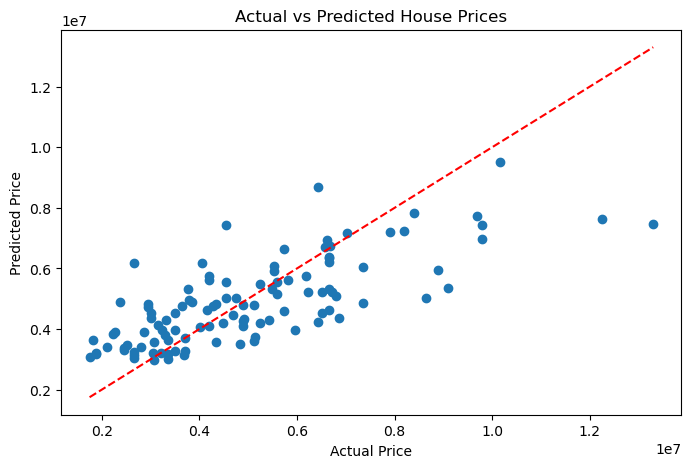

In [15]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")

# Reference line for perfect predictions
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.show()

In [12]:
new_house = pd.DataFrame({
    'area': [5000],
    'bedrooms': [3],
    'bathrooms': [2],
    'stories': [2],
    'parking': [1]
})

print("Predicted Price:", model.predict(new_house)[0])

Predicted Price: 5749400.492159771


## Titanic Dataset

In [18]:
import pandas as pd


In [19]:
tit = pd.read_csv(r"C:\Users\pruth\Downloads\archive\Titanic-Dataset.csv")

In [22]:
tit.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [23]:
tit.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [24]:
print(tit.columns)
print(tit.isnull().sum())

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [25]:
import pandas as pd

# Fill missing values
tit['Age'] = tit['Age'].fillna(tit['Age'].median())
tit['Embarked'] = tit['Embarked'].fillna(tit['Embarked'].mode()[0])

# Remove columns not needed for this model
tit = tit.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])

# Encode categorical columns
tit['Sex'] = tit['Sex'].map({'male': 0, 'female': 1})
tit = pd.get_dummies(tit, columns=['Embarked'], dtype=int)

# Check missing values
print(tit.isnull().sum())
print(tit.head())

Survived      0
Pclass        0
Sex           0
Age           0
SibSp         0
Parch         0
Fare          0
Embarked_C    0
Embarked_Q    0
Embarked_S    0
dtype: int64
   Survived  Pclass  Sex   Age  SibSp  Parch     Fare  Embarked_C  Embarked_Q  \
0         0       3    0  22.0      1      0   7.2500           0           0   
1         1       1    1  38.0      1      0  71.2833           1           0   
2         1       3    1  26.0      0      0   7.9250           0           0   
3         1       1    1  35.0      1      0  53.1000           0           0   
4         0       3    0  35.0      0      0   8.0500           0           0   

   Embarked_S  
0           1  
1           0  
2           1  
3           1  
4           1  


In [26]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

X = tit.drop('Survived', axis=1)
y = tit['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Logistic Regression Accuracy: 0.8100558659217877
Confusion Matrix:
[[90 15]
 [19 55]]


In [27]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Decision Tree
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)

print("Decision Tree Accuracy:",
      accuracy_score(y_test, dt_pred))

# KNN with feature scaling
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)

print("KNN Accuracy:",
      accuracy_score(y_test, knn_pred))

Decision Tree Accuracy: 0.7877094972067039
KNN Accuracy: 0.8044692737430168


In [28]:
for depth in [1, 2, 3, 5, 10, None]:
    dt = DecisionTreeClassifier(
        max_depth=depth, random_state=42
    )
    dt.fit(X_train, y_train)

    pred = dt.predict(X_test)

    print(
        "Max Depth:", depth,
        "Accuracy:", round(accuracy_score(y_test, pred), 4)
    )

Max Depth: 1 Accuracy: 0.7821
Max Depth: 2 Accuracy: 0.7654
Max Depth: 3 Accuracy: 0.7989
Max Depth: 5 Accuracy: 0.7989
Max Depth: 10 Accuracy: 0.7933
Max Depth: None Accuracy: 0.7877
